<a href="https://colab.research.google.com/github/kavy988/ai-ml-dl-learning/blob/main/machine-learning/ch08_Reinforcenment_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reinforcement Learning


**In this chapter we will go though**  -

What reinforcement learning is and what it’s good at, then present three of the most
important families of techniques in deep reinforcement learning: policy gradients, deep Q-networks (including a
discussion of Markov decision processes), and lastly, actor-critic methods, including the popular PPO


**What Is Reinforcement Learning** ?

In reinforcement learning, a software agent makes observations and takes actions within an environment, and in return it
receives rewards from the environment. Its objective is to learn to act in a way that will maximize its expected rewards over time.

In short, the agent acts in the environment and learns
by trial and error to maximize its pleasure and minimize its pain.

**Few Examples** -

* The agent can be the program controlling a robot. In this case, the environment is the real world, the agent
observes the environment through a set of sensors, such as cameras and touch sensors, and its actions consist of
sending signals to activate motors. It may be programmed to get positive rewards whenever it approaches the
target destination, and negative rewards whenever it wastes time or goes in the wrong direction.


- The agent can be the program controlling Ms. Pac-Man. In this case, the environment is a simulation of the Atari
game, the actions are the nine possible joystick positions (upper left, down, center, and so on), the observations
are screenshots, and the rewards are just the game points.


- Similarly, the agent can be the program playing a board game such as Go. It only gets a reward if it wins.
The agent does not have to control a physically (or virtually) moving thing. For example, it can be a smart
thermostat, getting positive rewards whenever it is close to the target temperature and saves energy, and negative
rewards when humans need to tweak the temperature, so the agent must learn to anticipate human needs.

- The agent can observe stock market prices and decide how much to buy or sell every second. Rewards are
obviously the monetary gains and losses.

Note that there may not be any positive rewards at all; for example, the agent may move around in a maze, getting a
negative reward at every time step, so it had better find the exit as quickly as possible!

Many other examples of
tasks to which reinforcement learning is well suited, such as self-driving cars, recommender systems, placing ads on a
web page, or controlling where an image classification system should focus its attention.

## 0.Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
from pathlib import Path

NOTE - Use Gpu for this notebook

## 1.Policy Gradients -

A specific approach to solve the Rl problems.

Policy gradients is a family of algorithms built around two ideas:

- Policy = the agent's decision-making rule: given an observation, it outputs an action (here, a neural network).

- Gradient = you improve that policy directly by computing gradients of the expected reward with respect to the policy's parameters, then doing gradient ascent (nudge the weights so actions that led to higher rewards become more likely).


The algorithm a software agent uses to determine its actions is called its policy.

The policy can be any algorithm you can
think of, such as a neural network taking observations as inputs and outputting the action to take

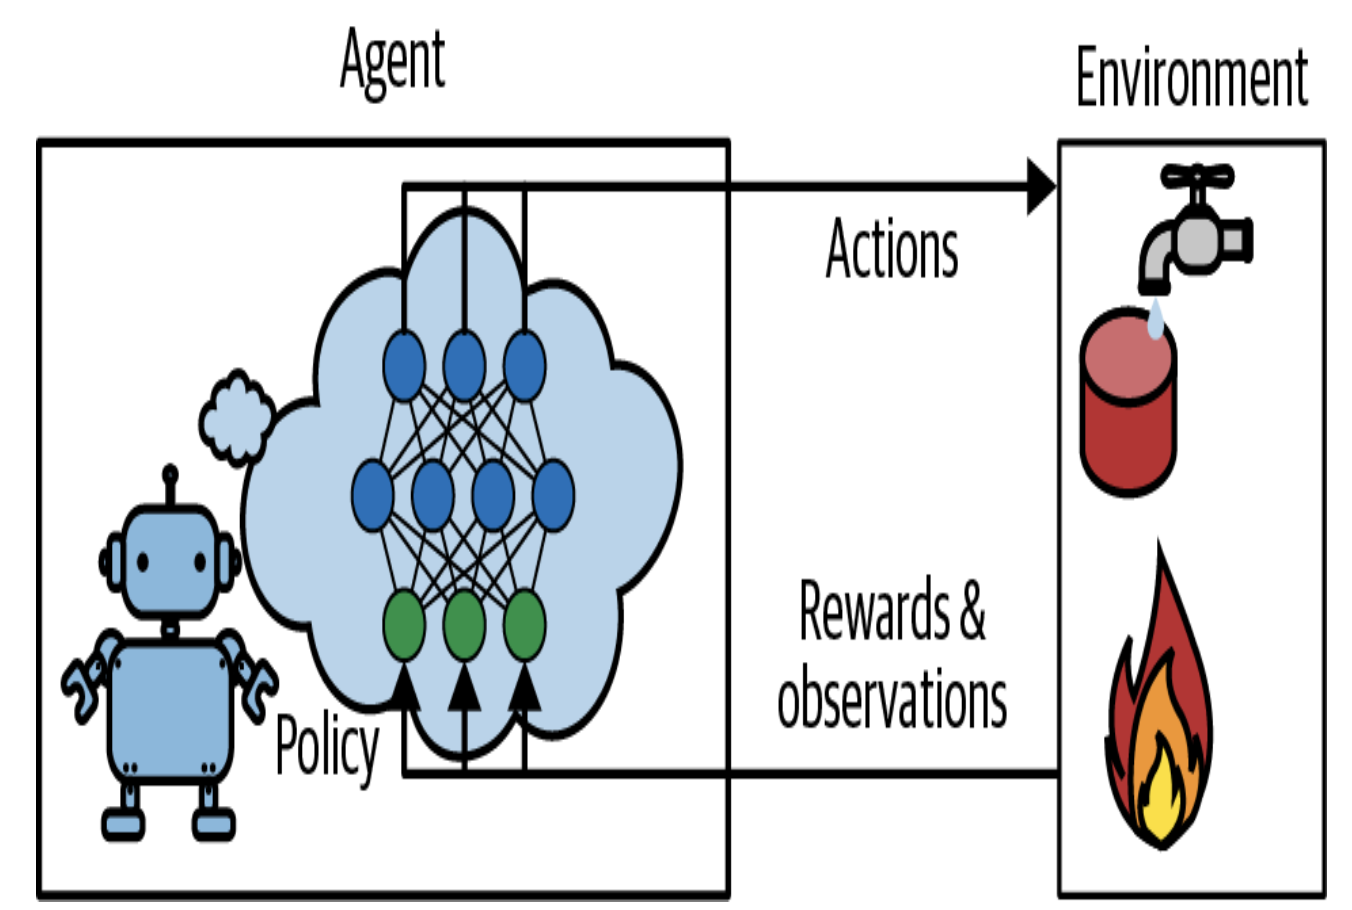

Note -

1. Policy doesn't need to be deterministic . Infact , in same cases it doesn't even have to observe the environment as long as it can get the rewards.
(e.g - vaccum cleaner robot)

2. Policy involves some randomness , it's called a stochastic policy.

3. One approach , to use optimization techniques by evaluating the gradients of the rewards with regard to the
policy parameters, then tweaking these parameters by following the gradients toward higher rewards. Algorithms that
follow this strategy are known as policy gradient (PG) algorithms.

But before we can implement them, we first need to
create an environment for the agent to live in⁠ —so it’s time to introduce the Gymnasium library.



---



## 2.Introduction to the Gymnasium Library

- One of the challenges of reinforcement learning is that in order to train an agent, you first need to have a working environment.



E.g. -
- If you want to program an agent that will learn to play an Atari game, you will need an Atari game
simulator.

- If you want to program a walking robot, then the environment is the real world, and you can directly train your
robot in that environment.



**Limits**

-  training is hard and slow in the real world, so you generally need a
simulated environment at least for bootstrap training.

- For example, you might use a library like PyBullet or MuJoCo for
3D physics simulation.

The Gymnasium library is an open source toolkit that provides a wide variety of simulated environments  that you can use to train agents, compare them, or develop new
RL algorithms

In [2]:
# start by importing Gymnasium and making an environment

import gymnasium as gym
env = gym.make("CartPole-v1" , render_mode = "rgb_array" , max_episode_steps = 1000)


The CartPole (version 1) is a very simple environment composed of a cart that can move left or right, and pole placed vertically on top of it. The agent must move the cart left or right to keep the pole upright.

**NOTE**: `gym.envs.registry` is a dictionary containing all available environments:

In [3]:
# Let's use the dictionary
# it lists a few of the environments available in Gymnasium.
envs = gym.envs.registry
sorted(envs.keys())[:5] + ["..."]
# ["..."] - it's nothing , jsut to make us understand that there are more environemnts

['Acrobot-v1', 'Ant-v2', 'Ant-v3', 'Ant-v4', 'Ant-v5', '...']

**Note**

The registry values are environment specification .

- that means each value in the gym.envs.registry dictionary isn't an environment itself, but a spec (blueprint) describing how to create that environment.


for e.g - An EnvSpec stores things like:

* id: the name, e.g. 'CartPole-v1'

* entry_point: which Python class to use to build it (e.g. CartPoleEnv)

* max_episode_steps: the step limit per episode (500 for CartPole-v1)

* reward_threshold: the score considered "solved"


In [4]:
# Let's code it out
envs["CartPole-v1"]

EnvSpec(id='CartPole-v1', entry_point='gymnasium.envs.classic_control.cartpole:CartPoleEnv', reward_threshold=475.0, nondeterministic=False, max_episode_steps=500, order_enforce=True, disable_env_checker=False, kwargs={}, namespace=None, name='CartPole', version=1, additional_wrappers=(), vector_entry_point='gymnasium.envs.classic_control.cartpole:CartPoleVectorEnv')

**Extra** - we can print a nice list with gym.pprint
_
registry(). The Atari environments will only be available once we start
the ALE emulator.

In [5]:
# Extra - list
gym.pprint_registry()

===== classic_control =====
Acrobot-v1             CartPole-v0            CartPole-v1
MountainCar-v0         MountainCarContinuous-v0 Pendulum-v1
===== phys2d =====
phys2d/CartPole-v0     phys2d/CartPole-v1     phys2d/Pendulum-v0
===== box2d =====
BipedalWalker-v3       BipedalWalkerHardcore-v3 CarRacing-v3
LunarLander-v3         LunarLanderContinuous-v3
===== toy_text =====
Blackjack-v1           CliffWalking-v1        CliffWalkingSlippery-v1
FrozenLake-v1          FrozenLake8x8-v1       Taxi-v4
===== tabular =====
tabular/Blackjack-v0   tabular/CliffWalking-v0
===== None =====
Ant-v2                 Ant-v3                 GymV21Environment-v0
GymV26Environment-v0   HalfCheetah-v2         HalfCheetah-v3
Hopper-v2              Hopper-v3              Humanoid-v2
Humanoid-v3            HumanoidStandup-v2     InvertedDoublePendulum-v2
InvertedPendulum-v2    Pusher-v2              Reacher-v2
Swimmer-v2             Swimmer-v3             Walker2d-v2
Walker2d-v3
===== mujoco =====
Ant-v4    



```
The CartPole environment
```



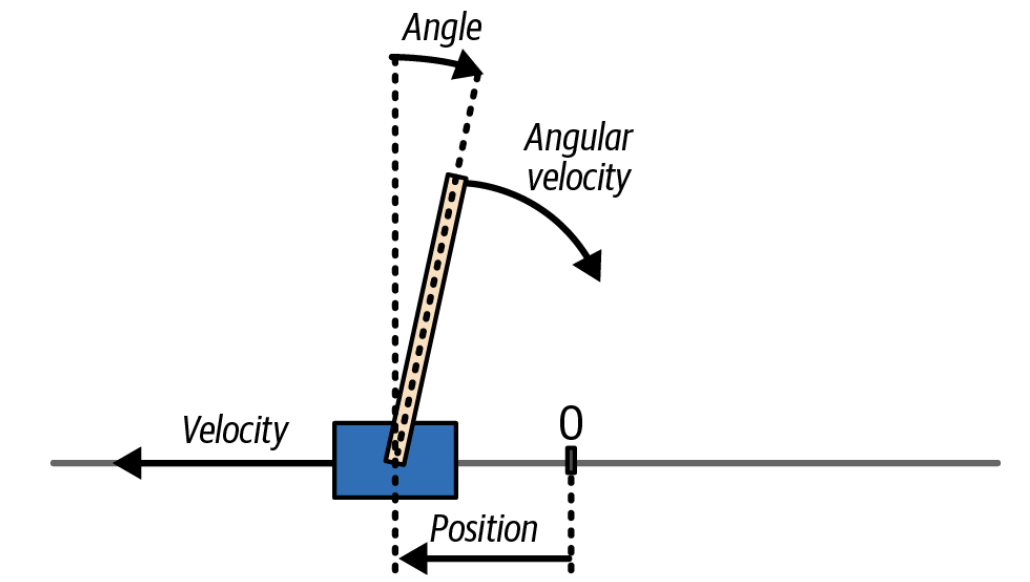

**NOTE** - After the environment is created, you must initialize it using the reset() method, optionally specifying a random seed.

In [6]:
obs, info = env.reset(seed = 42)
obs

array([ 0.0273956 , -0.00611216,  0.03585979,  0.0197368 ], dtype=float32)

**NOTE**

`reset()` doesn't run the cart-pole at all. It just sets up a fresh episode and gives you the starting observation. Nothing has moved yet.

The array is the initial state of the cart and pole, right at the start:

* 0.0273956: cart position (almost at the center)

* -0.00611216: cart velocity (almost not moving)

* 0.03585979: pole angle (almost vertical)

* 0.0197368: pole angular velocity (barely rotating)

**TBR**

The
reset() method also returns a dictionary that may contain extra environment-specific information. This can be useful
for debugging and sometimes for training

In [7]:
# currently no extra info as it's not moved yet
info

{}

Let’s call the render() method to render this environment as an image. Since we set `render_mode = "rgb_array"`
when creating the environment, the image will be returned as a NumPy array (you can then use Matplotlib’s imshow()
function to display this image):

An environment can be visualized by calling its `render()` method. If you set `render_mode` to `"rgb_array"` when creating the environment, then this will return a NumPy array.

In [8]:
img = env.render()
img.shape #  height, width, channels (3 = Red, Green, Blue)


/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


(400, 600, 3)

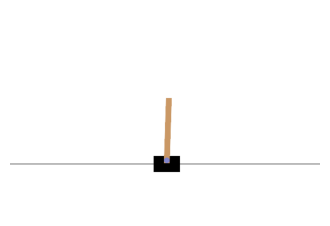

In [9]:
# Let's plot it out

# creating an function to call anytime
def plot_environment(env , figsize = (2,2)):
  plt.figure(figsize = (4,3))
  img = env.render()
  plt.imshow(img)
  plt.axis("off")
  return img

plot_environment(env)
plt.show()

Now le's figure out how to interact with an environemnt

- Your agent will need to select an action from an "action space" (the set of possible actions). Let's see what this environment's action space looks like:

Or Now let's ask the environment what actions are possible


In [10]:
env.action_space

Discrete(2)

Discrete(2) means that the possible actions are integers 0 and 1, which represent accelerating left or right. Other
environments may have additional discrete actions, or other kinds of actions (e.g., continuous). Since the pole is leaning
toward the right (obs[2] > 0), let’s accelerate the cart toward the right:

In [11]:
action = 1 # accelerating right
obs , reward, done , truncated , info = env.step(action)
obs

array([ 0.02727336,  0.18847767,  0.03625453, -0.26141977], dtype=float32)

In [12]:
reward , done , truncated , info

(1.0, False, False, {})

Notice that the cart is now moving toward the right (`obs[1] > 0`). The pole is still tilted toward the right (`obs[2] > 0`), but its angular velocity is now negative (`obs[3] < 0`), so it will likely be tilted toward the left after the next step.

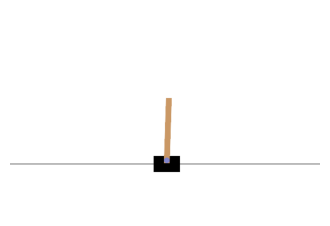

In [13]:
# extra  - let's check it now , wheter it shifted or not
plot_environment(env)
plt.show()

As u can see the pole tilted left.


The step() method executes the desired action and returns five values:


In [14]:
reward

1.0

When the game is over, the environment returns `done=True`. In this case, it's not over yet:

In [15]:
done

False

Some environment wrappers may want to interrupt the environment early. For example, when a time limit is reached or when an object goes out of bounds. In this case, `truncated` will be set to `True`. In this case, it's not truncated yet:

In [16]:
truncated

False

Finally, `info` is an environment-specific dictionary that can provide some extra information that you may find useful for debugging or for training. For example, in some games it may indicate how many lives the agent has.

In [17]:
info

{}


The sequence of steps between the moment the environment is reset until it is done or truncated is called an "episode". At the end of an episode (i.e., when `step()` returns `done=True` or `truncated=True`), you should reset the environment before you continue to use it.

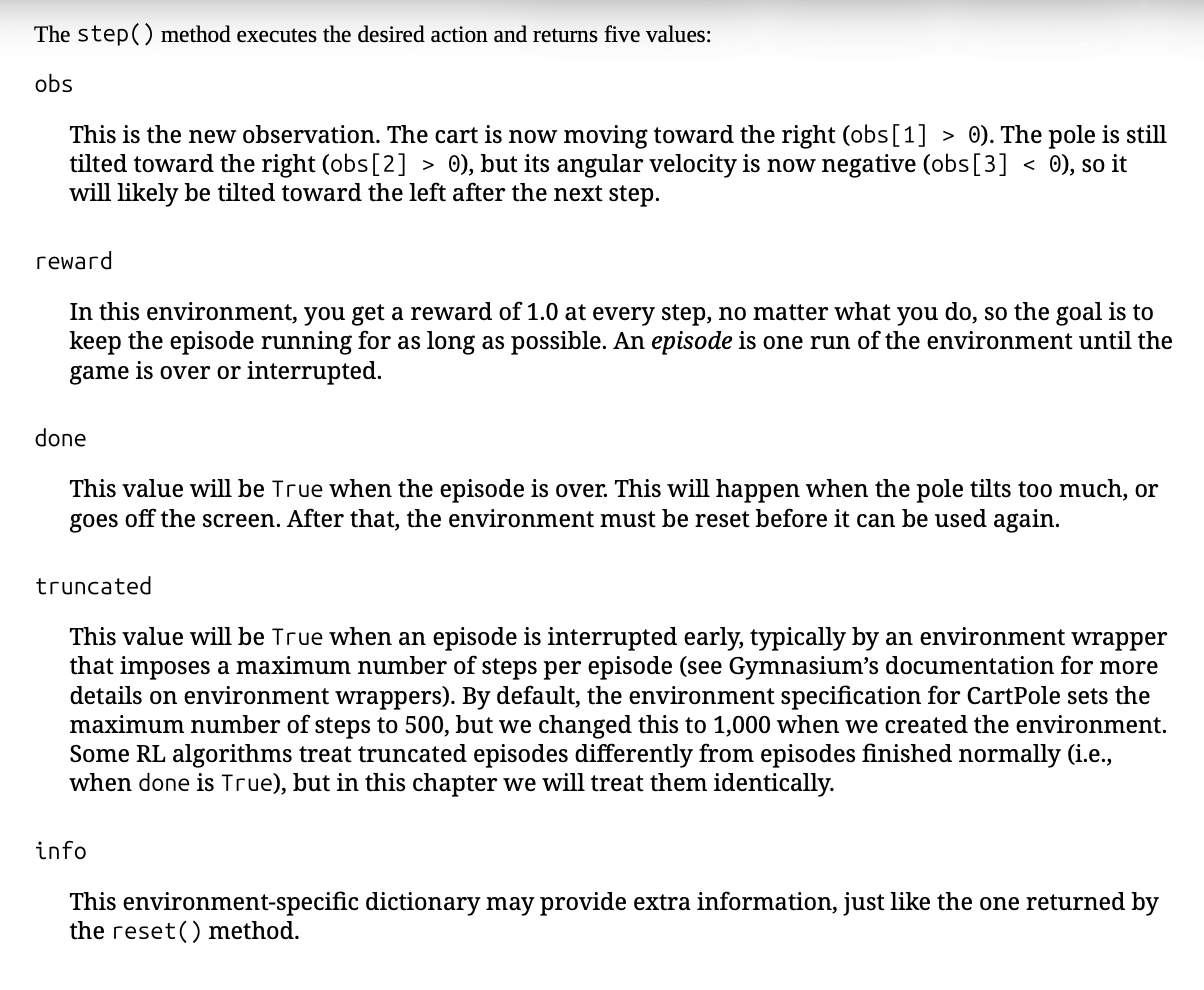

**TBR**

Once you have finished using an environment—possibly after many episodes—you should call its close() method
to free resources.




---



Let’s hardcode a simple policy that accelerates left when the pole is leaning toward the left and accelerates right when the
pole is leaning toward the right. We will run this policy to see the average rewards it gets over 500 episodes:

In [18]:
def basic_policy(obs):
  angle = obs[2] # pole angle , -ve means leaning left and +ve means leaning right
  return 0 if angle < 0 else 1 # go left if leaning left , otherwise go right

totals =[]  # Stores the final score of each episode
for episode in range(500): # Runs 500 separate games
  total_rewards = 0 # Reward counter for this episode
  obs, info = env.reset(seed = episode) # if the episode ended by failure, i.e. the pole fell too far or the cart went off the track
  while True: # if the episode was cut off by the time limit (500 steps in CartPole-v1
    # no risk of infinite loop : will be truncated after 1k steps
    action = basic_policy(obs)
    obs,reward, done , truncated , info = env.step(action)
    total_rewards += reward
    if done or truncated:
      break
  totals.append(total_rewards)


In [19]:
print(np.mean(totals).round(2), np.std(totals).round(2), min(totals) , max(totals))

41.7 8.39 24.0 63.0


That concludes that even with 500 tries, this policy never managed to keep the pole upright for more than 63 consecutive steps. Not great. If
you look at the simulation in this chapter’s notebook, you will see that the cart oscillates left and right more and more
strongly until the pole tilts too much. A neural network can do better!

In [20]:
# extra code – this cell displays an animation of one episode
import matplotlib.pyplot as plt
import matplotlib.animation as animation

def update_scene(num, frames, patch):
    patch.set_data(frames[num])
    return patch,

def plot_animation(frames, repeat=False, interval=40):
    fig = plt.figure()
    patch = plt.imshow(frames[0])
    plt.axis('off')
    anim = animation.FuncAnimation(
      fig, update_scene, fargs=(frames, patch),
      frames=len(frames), repeat=repeat, interval=interval)
    plt.close()
    return anim

def show_one_episode(policy, n_max_steps=200, seed=42):
    frames = []
    env = gym.make("CartPole-v1", render_mode="rgb_array")
    np.random.seed(seed)
    obs, info = env.reset(seed=seed)
    for step in range(n_max_steps):
        frames.append(env.render())
        action = policy(obs)
        obs, reward, done, truncated, info = env.step(action)
        if done or truncated:
            break
    env.close()
    return plot_animation(frames)

show_one_episode(basic_policy)

In [21]:
# Extra
from IPython.display import HTML

anim = show_one_episode(basic_policy)
HTML(anim.to_jshtml())



---



**NOTE**

- Action space: the options available (CartPole: left or right).

- Policy: the decision rule that picks one of those options based on what the agent observes.



---



## 3.Neural Network Policies




This neural network will take an observation as input, and it will output the action to
be executed, just like the policy we hardcoded earlier.

More precisely, it will estimate a probability for each action, then it
will select an action randomly, according to the estimated probabilities

In the case of the CartPole
environment, there are just two possible actions (left or right), so we only need one output neuron. It will output the
probability p of action 1 (right), and of course the probability of action 0 (left) will be 1 – p. For example, if it outputs
0.7, then we will pick action 1 with 70% probability, or action 0 with 30% probability (this is a Bernoulli distribution
with p = 0.7).

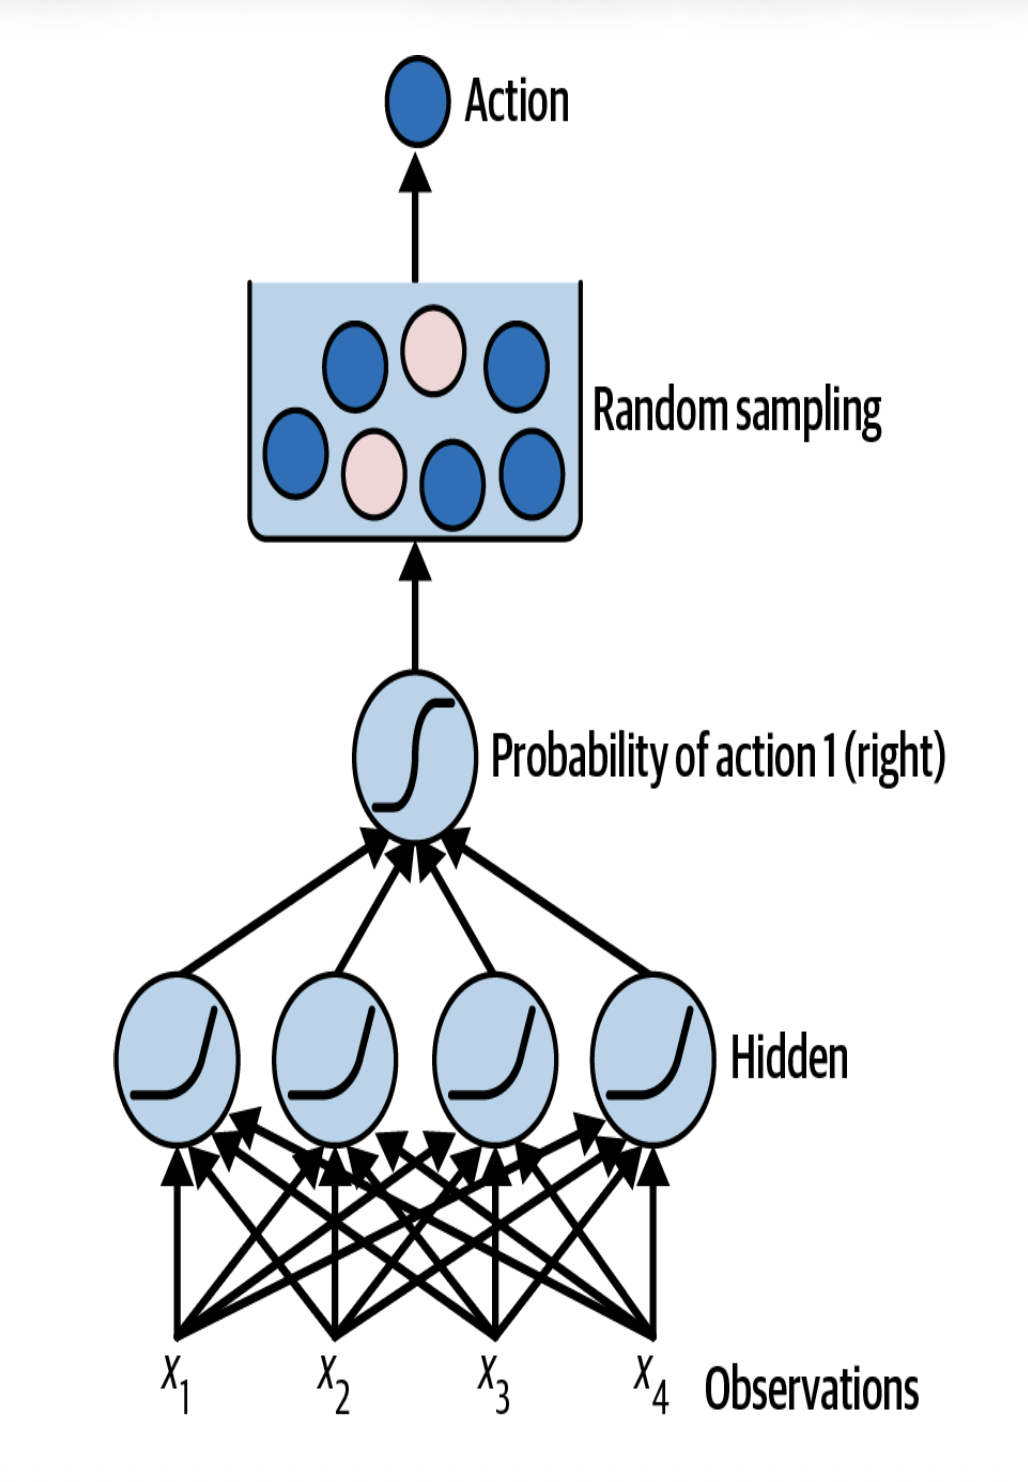

- You may wonder why we are picking a random action based on the probabilities given by the neural network, rather than
just picking the action with the highest score. This approach lets the agent find the right balance between exploring new
actions and exploiting the actions that are known to work well


**E.g**

* U in a restaurant ,ordering food, now u ordereding random meal and if u like it , u will increase the probability of ordering it again , but u may not gonna make it 100% or maybe does

**Note**

- Here in the cartpole , we ignoring the past actions and observations , but there can always be hidden state info but here it's not the case so ignored.





---



Overview - this policy network is a small MLP(Multi-Layer perceptron)


Let’s use PyTorch to implement a basic neural network policy  for CartPole:


In [22]:
# MLP

import torch
import torch.nn as nn

class PolicyNetwork(nn.Module):
  def __init__(self):
    super().__init__()
    self.net = nn.Sequential(
      nn.Linear(in_features = 4, out_features = 5),# 4 observation values -> 5 hidden neurons
      nn.ReLU(), # non-linearity so the network can learn complex rules
      nn.Linear(in_features = 5, out_features = 1)  # 5 hidden neurons -> 1 output (the action score)
    )

  def forward(self , state)  :
    return self.net(state) # obs in action score out




---



For performance and numerical stability, we don’t add a sigmoid function at the end, so the network will actually output
logits rather than probabilities.

In [23]:
# Next let’s define a function that will use this policy
# network to choose an action:

import torch

def choose_action(model, obs):
    # Ensure float32 and match the model's device (CPU/GPU)
    device = next(model.parameters()).device
    state = torch.as_tensor(obs, dtype=torch.float32, device=device)

    logit = model(state)
    dist = torch.distributions.Bernoulli(logits=logit)  # Fixed: distributions (plural)
    action = dist.sample()
    log_prob = dist.log_prob(action)

    return int(action.item()), log_prob

The function takes a single observation, converts it to a tensor, and passes it to the policy network to get the logit for
action 1 (right). It then creates a Bernoulli probability distribution with this logit, and it samples an action from it: this
distribution will output 1 (right) with probability p = exp(logit) / (1 + exp(logit)), and 0 (left) with probability 1 – p. If
there were more than two possible actions, you would use a Categorical distribution instead. Lastly, we compute the
log probability of the sampled action (i.e., either log(p) or log(1 – p)): this log probability will be needed later for
training.


**TIP**


If the action space is continuous, you can use a Gaussian distribution instead of a Bernoulli or categorical
distribution. Instead of predicting logits, the policy network must predict the mean and standard deviation (or the log
of the standard deviation) of the distribution. The log of the standard deviation is often clipped to ensure the
distribution is neither too wide nor too narrow.



---



Current Progress so far

OK, we now have a neural network policy that can take an environment state (in this case, a single observation) and
choose an action. But how do we train it?



---



### 3.1 Evaluating Actions: The Credit Assignment Problem


If we knew what the best action was at each step, we could train the neural network as usual by minimizing the cross-
entropy between the estimated probability distribution and the target probability distribution. It would just be regular
supervised learning. However, in reinforcement learning the only guidance the agent gets is through rewards, and rewards
are typically sparse and delayed. For example, if the agent manages to balance the pole for a total of 100 steps, how can it
know which of the 100 actions it took were good, and which of them were bad? `All it knows is that the pole fell after the
last action, but surely this last action is not entirely responsible. This is called the **credit assignment** problem: when the
agent gets a reward (or a penalty), it is hard for it to know which actions should get credited (or blamed) for it. ` Think of a
dog that gets rewarded hours after it behaved well; will it understand what it is being rewarded for?


To simplify credit assignment, a common strategy is to evaluate an action based on the sum of all the rewards that come
after it, applying a discount factor, _γ (gamma), at each step. This sum of discounted rewards is called the action’s return.
Consider the example in Figure 19-6. If an agent decides to go right three times in a row and gets +10 reward after the
first step, 0 after the second step, and finally –50 after the third step, then assuming we use a discount factor γ = 0.8, the
first action will have a return of 10 + γ × 0 + γ2 × (–50) = –22.

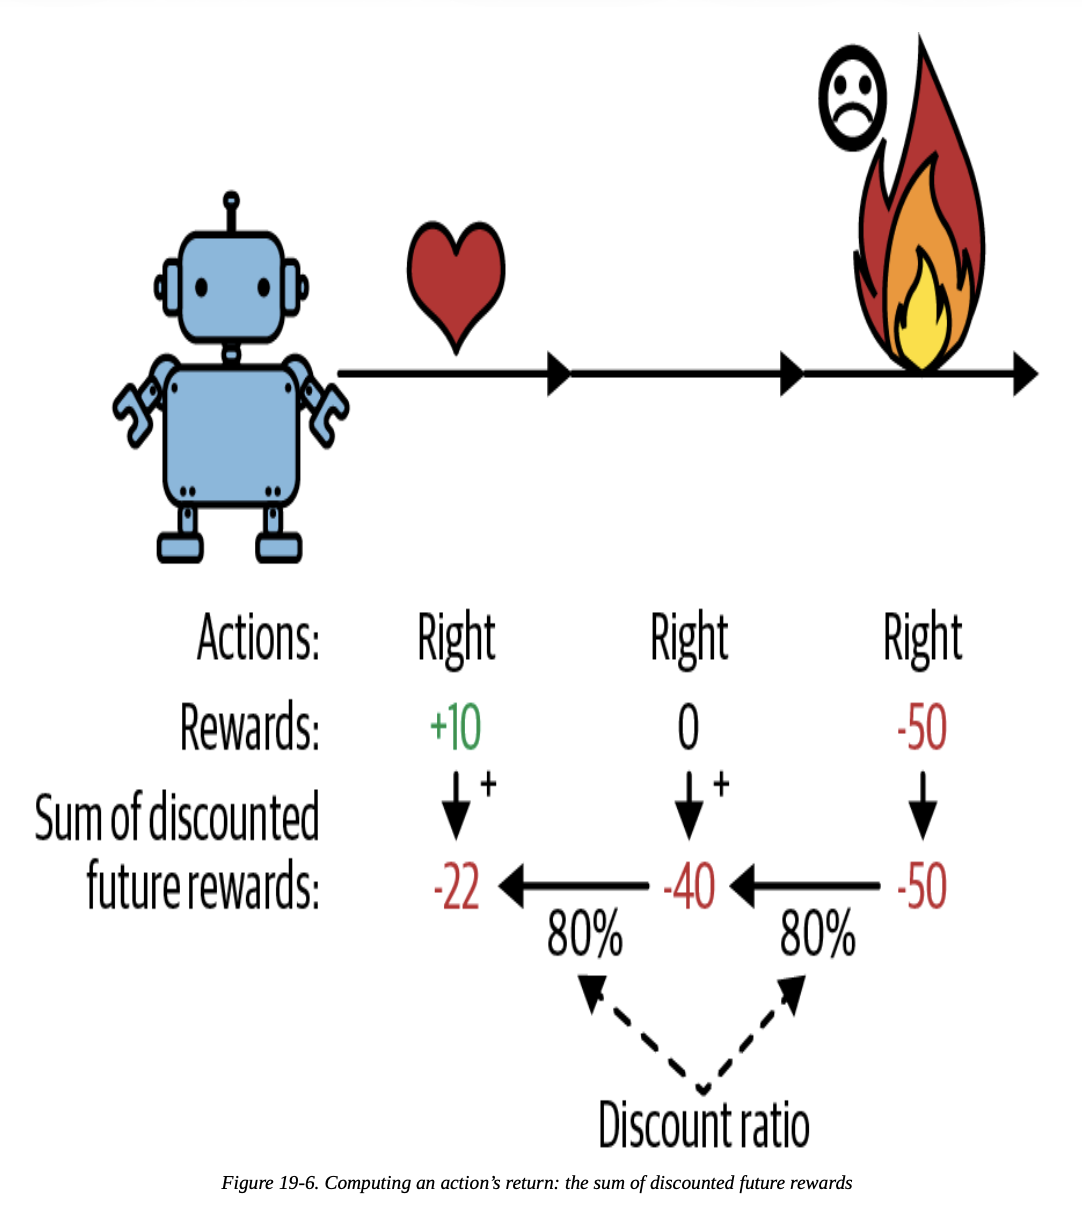

In [24]:
# So let's code it out
# calculating rewards in short with discount factor

def compute_returns(rewards , discount_factor):
  returns = rewards[:] # copy the rewards

  for step in range(len(returns) -1 , 0 , -1):
    returns[step - 1] += returns[step] * discount_factor

  return torch.tensor(returns)


In [25]:
# this fn produces the expected results
compute_returns([10,0,-50] , discount_factor = 0.8)

tensor([-22., -40., -50.])

**NOTE**

- If the discount factor is close to 0, then future rewards won’t count for much compared to immediate rewards.
Conversely, if the discount factor is close to 1, then rewards far into the future will count almost as much as immediate
rewards. Typical discount factors vary from 0.9 to 0.99


- In the CartPole environment, actions have fairly
short-term effects, so choosing a low discount factor of 0.95 seems reasonable, and it will help with credit assignment,
making training faster and more stable.

* However, if the discount factor is set too low, then the agent will learn a
suboptimal strategy, focusing too much on short-term gains.




---



Now that we have a way to evaluate each action, we are ready to train our first agent using policy gradients. Let’s see
how.


---



### 3.2 Solving the CartPole Using Policy Gradients


- Policy gradient algorithms optimize the parameters of a policy by following the gradients toward
higher rewards.

- One popular PG algorithm, called REINFORCE (or Monte Carlo PG).

**General principle of REINFORCE**

1.  First, let the neural network policy play the game for an episode, and record the rewards and estimated log
probabilities.

2. Then compute each action’s return, using the function defined in the previous sections.

3. If an action’s return is positive, it means that the action was probably good, and you want to make this action
even more likely to be chosen in the future. Conversely, if an action’s return is negative, you want to make this
action less likely. To achieve this, you can minimize the REINFORCE loss defined in the below equation



```
Equation for REINFORCE loss
```

$\mathscr{L}(\boldsymbol{\theta}) = -\sum_{t} \log \pi_{\boldsymbol{\theta}}(a_t | s_t) \cdot r_t$


In this equation, πθ(at|st) is the policy network’s estimated probability for action at, given state st (where t is the time
step), and rt is the observed return of this action; θ represents the model parameters.




---



In [26]:
# Let's code it out

def run_episode(model , env , seed = None):
  log_probs , rewards = [] , [] # to store
  obs , info = env.reset(seed = seed) # Puts the cart and pole back in the starting position and gives you the initial 4 observations.

  while True: # the environment will truncate the episode if it's too long , means stop
    action , log_prob = choose_action(model, obs)# pick a move asked by policy network
    obs , reward , done , truncated , _info = env.step(action) # executing that move and put into gymnasium

    # Storing results
    log_probs.append(log_prob)
    rewards.append(reward)

    if done or truncated :
      return log_probs , rewards


The function first resets the environment to start a new episode. For reproducibility, we pass a seed to the reset()
method. Then comes the game loop: at each iteration, we pass the current environment state (i.e., the last observation) to
the choose
_
action() method we defined earlier. It returns the chosen action and its log probability. We then call the
environment’s step() method to execute the action. This returns a new observation (a NumPy array), a reward, two
booleans indicating whether the game is over or truncated, and an info dict (which we can safely ignore in the case of
CartPole). We record the log probabilities and rewards in two lists, which we return when the episode is over.

In [27]:
# Let's train

def train_reinforce(model , optimizer , env , n_episodes , discount_factor):
  for episode in range(n_episodes):
    seed = torch.randint(0, 2**32 , size = ()).item() # every episode , with different position and other things

    log_probs , rewards = run_episode(model , env , seed = seed)

    returns = compute_returns (rewards , discount_factor)
    std_returns = (returns - returns.mean()) / (returns.std() + 1.e-7)

    losses = [-logp * rt for logp , rt in zip(log_probs , std_returns)]

    loss = torch.cat(losses).sum()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    print(f"\rEpisode {episode + 1}, reward : {sum(rewards):.2f}" , end = " ")


**Explanation**

At each training iteration, the function runs an episode and gets the log probabilities and
reward .

Then it computes the return for each action.

Next, it standardizes the returns (i.e., it subtracts the mean return
and divides by the standard deviation, plus a small value to avoid division by zero).

This standardization step is optional
but it’s a common and recommended tweak to the REINFORCE algorithm, as it stabilizes training.

Next, the function
computes the REINFORCE loss using Equation of `Reinforce_loss`, and it performs an optimizer step to minimize the loss.

In [28]:
# As we already built and train a policy network , now let's see how it works
torch.manual_seed(42)

# creating our first model
model = PolicyNetwork()

# set the optimizer and lr
optimizer = torch.optim.NAdam(model.parameters() , lr = 0.06)

# let's do the training
train_reinforce(model , optimizer , env , n_episodes = 200 , discount_factor = 0.95)


Episode 200, reward : 131.00 

**Note**

This is a simple policy gradient algorithm we just trained for cartpole .

 because its return estimates are extremely noisy, especially when good
actions are mixed with bad ones. However, it is the foundation of more powerful algorithms, such as actor-critic
algorithms

**Conclusion**


the REINFORCE algorithm is quite unstable: the agent may improve for a while during training, then forget
everything catastrophically, learn again, forget, learn, etc

`why`
- because the training
samples are not independent and identically distributed.
As the agent progresses, it explores different parts of the environment, and it can
forget everything about other parts.



---



## 4.Value-Based Methods


Another popular family of algorithms.



Whereas PG algorithms directly try to optimize the policy to increase rewards, value-based methods are less direct: the
agent learns to estimate the value of each state (i.e., the expected return), or the value of each action in a given state, then
it uses this knowledge to decide how to act. To understand these algorithms, we must first discuss Markov decision
processes (MDPs).

### 4.1 Markov Decision Processes

The mathematician Andrey Markov studied stochastic processes with no memory, called Markov
chains. Such a process has a fixed number of states, and it randomly evolves from one state to another at each step. The
probability for it to evolve from a state s to a state s′ is fixed, and it depends only on the pair (s, s′), not on past states.


This is why we say that the system has no memory.

A Markov Decision Process (MDP) is the mathematical framework used to model almost all Reinforcement Learning problems.

It builds on two simple ideas:

1. The Markov Property: The future depends only on your current state, not on the history of how you got there. (In CartPole, knowing the cart's current position, velocity, and pole angle is all you need—you don't need a replay of the last 50 frames).

2. Decisions & Rewards: Unlike a passive Markov chain where things just happen randomly, an MDP lets an agent choose actions at each step to steer where it goes next and collect rewards.


The 5 Building Blocks of an MDPEvery MDP is defined by five pieces:

1. States ($s$): All possible situations the environment can be in (e.g., obs).

2. Actions ($a$): The moves available to the agent (0 or 1).

3. Transition Probabilities $T(s, a, s')$: The probability of landing in state $s'$ if you take action $a$ in state $s$ (because environments can have randomness, like wind or slippery floors).

4. Rewards $R(s, a, s')$: The immediate reward received when transitioning from $s$ to $s'$ via action $a$.

5. Discount Factor ($\gamma$): How much the agent values future rewards vs. immediate rewards (usually 0.9 to 0.99).

### 4.2 Bellman optimality equation


Richard Bellman’s Bellman Optimality Equation is the mathematical engine that lets an agent figure out how valuable every state (and action) actually is inside a Markov Decision Process.




```
Bellman optimality equation
```


$$V^*(s) = \max_{a} \sum_{s'} T(s, a, s') \left[ R(s, a, s') + \gamma V^*(s') \right]$$

In this equation:



* **$V^*(s)$:** Optimal value of current state $s$ (max expected discounted return from $s$ onward).


* **$s$:** Current state of the environment.


* **$a$:** Action taken by the agent in state $s$.


* **$\max_a$:** Picks the single best action $a$ that yields the highest expected value.


* **$s'$:** Next state the agent lands in after taking action $a$.


* **$T(s, a, s')$:** Probability of transitioning from state $s$ to $s'$ when taking action $a$.


* **$R(s, a, s')$:** Immediate reward earned for transitioning from $s$ to $s'$ via action $a$.


* **$\gamma$:** Discount factor ($0$ to $1$) scaling the importance of future rewards.


* **$V^*(s')$:** Optimal value of the next state $s'$.

### 4.3 Q-values iteration algorithm


Knowing the optimal state values can be useful, in particular to evaluate a policy, but it does not give us the optimal
policy for the agent. Luckily, Bellman found a very similar algorithm to estimate the optimal state-action values,
generally called Q-values (quality values).


The optimal Q-value of the state-action pair (s, a), denoted Q*(s, a), is the sum
of discounted future rewards the agent can expect on average starting from state s if it chooses action a, but before it sees
the outcome of this action, assuming it acts optimally after that action.

Q-Value Iteration is the exact same Bellman scoring idea, except instead of scoring just the state ($V(s)$), it scores every (state, action) pair—written as $Q(s, a)$ (Quality of taking action $a$ in state $s$).


**How It Works in 3 Steps**

1. Start at zero: Set $Q(s, a) = 0$ for every possible state and action.


2. Update repeatedly: Run the Bellman equation for Q-values over and over until the numbers stop changing:



```
Equation -  Q-value iteration algorithm
```

$$Q_{k+1}(s, a) \leftarrow \sum_{s'} T(s, a, s') \left[ R(s, a, s') + \gamma \cdot \max_{a'} Q_k(s', a') \right]$$

3. Pick the best move: Once trained, when the agent is in state $s$, it simply checks the table and picks the action $a$ with the highest $Q^*(s, a)$.



**Why it beats $V^*(s)$** :

With $V^*(s)$, the agent still needed to know the game's transition probabilities $T(s, a, s')$ to figure out which action leads to the best next state. With $Q^*(s, a)$, the best action is already baked into the score—just pick $\arg\max_a Q^*(s, a)$

***NOW***

Once you have the optimal Q-values, defining the optimal policy, denoted π
*(s), is trivial: when the agent is in state s, it
should choose the action with the highest Q-value for that state. The fancy math notation for this is
π* (s) = argm
x
Q* (s,a)

In [29]:
# Let’s apply this algorithm to the MDP represented
# First , we need to define the MDP

# Let's code it out
transition_prob = [ # shape [s(current_state), a(action), s'(next_state)]
    [[0.7, 0.3, 0.0], [1.0, 0.0, 0.0], [0.8, 0.2, 0.0]], # state 0
    [[0.0, 1.0, 0.0], None           , [0.0, 0.0, 1.0]], # state 1
    [None           , [0.8, 0.1, 0.1], None           ]  # state 2
    ]

rewards = [ # shape [s , a, s']
    [[+10, 0, 0], [0, 0, 0], [0, 0, 0]],
    [[0, 0, 0], [0, 0, 0], [0, 0, -50]],
    [[0, 0, 0], [+40, 0, 0], [0, 0, 0]]
    ]

possible_actions = [[0,1,2] , [0,2] , [1]] # me




---



Explaination from above how to check

[[0.7, 0.3, 0.0], [1.0, 0.0, 0.0], [0.8, 0.2, 0.0]], -> this whole is for state 0

so if we choose -> let's see what if offers

1. [0.7, 0.3, 0.0] -> this is called action(a0)


If you take this Action :70% stay in s0 | 30% move to s1 | 0% move to s2


[[+10, 0, 0] amd this is the corresponding reward for a0 for s0 . similarly others




---



### 4.4 Q-Values and it's table

Q_values is a n × m or may be cheat sheet (lookup table)

* Rows (m): Total number of states.

* Columns (n): Total number of actions

Each cell stores the total long-term score for taking that action in that state.

Now, we must initialize all the Q-values to zero
(except for the impossible actions, for which we set the Q-values to –∞):




**Why it's needed**

* Instant decisions during gameplay: Once the table is filled, the agent doesn't need transition_prob or rewards anymore—it just looks at its current state's row and picks the column with the highest score (np.argmax).

* Saves repeating math: Instead of recalculating future probabilities and discounted rewards from scratch on every move, it pre-computes all answers upfront.  


* Blocks illegal moves: Filling disallowed moves with -np.inf ensures the agent never picks an invalid action

In [30]:
# let's code it out
# creating an 3 * 3 Q-value where
Q_values = np.full((3,3), -np.inf ) # -np.inf for impossible actions

for state, actions in enumerate(possible_actions):
  Q_values[state, actions] = 0.0 # for all possible actions


Is code mein humne agent ke liye ek shuruati score table (Q_values) taiyar kiya hai:   Q_values = np.full((3,3), -np.inf):

- Ek 3 × 3 ka table banaya (3 states, 3 actions) aur shuru mein har dabbe mein -infinity (-np.inf) bhar diya—taaki jo moves illegal hain unka score hamesha sabse kam rahe aur agent unhe kabhi na chune.  

for state, actions in enumerate(possible_actions): ... = 0.0:
- Phir har state ke jo legal (allowed) actions hain, sirf unki value -inf se hata kar 0.0 kar di, taaki aage algorithm unhi ka sahi score calculate kar sake.

**G.K**

`Enumerate`: A built-in Python function that loops over a list and gives you both the index (0, 1, 2) and the item at the same time.

**Note**


In real-world RL, Q-values stop being a literal lookup table and become a neural network's prediction instead:

1. Small, discrete problems (Q-Table): When there are only a few states (like this 3 × 3 MDP), Q-values fit in an actual table ("cheat sheet").

2. Complex/continuous games (Deep Q-Networks / DQN): In real tasks (like CartPole's infinite decimal angles, or Atari pixels), a table would need infinite rows. Instead, a neural network takes the current state and predicts the Q-values on the fly.

3. Policy Gradients (No Q-values at all): Methods like REINFORCE (your PolicyNetwork earlier) skip Q-values completely and directly output action probabilities.

In [31]:
# now we gonna check and find the actual Q-values from running Bellman forumula repeatedly

gamma = 0.90 # discount factor
for iteration in range(50): # updating table 50 times , so that numbers get stablized
    Q_prev = Q_values.copy() # getting an copy
    for s in range(3):
        for a in possible_actions[s]: # updating all legal actions score
            Q_values[s, a] = np.sum([  # combines all next states transition scores, using formula
                transition_prob[s][a][sp] * (rewards[s][a][sp] + gamma * Q_prev[sp].max())
                for sp in range(3)
            ])

Q_values

array([[18.91891892, 17.02702702, 13.62162162],
       [ 0.        ,        -inf, -4.87971488],
       [       -inf, 50.13365013,        -inf]])

For example, when the agent is in state s0 and it chooses action a1, the expected sum of discounted future rewards is
approximately 17.0.

In [32]:
# to find actions of each state with the highest Q-value
# Let's use argmax

Q_values.argmax(axis = 1) # optimal action for each state

array([0, 0, 1])

This gives us the optimal policy for this MDP



---



## 5.Temporal Difference Learning

Reinforcement learning problems with discrete actions can often be modeled as Markov decision processes, but the agent
initially has no idea what the transition probabilities are (it does not know T(s, a, s′)), and it does not know what the
rewards are going to be either (it does not know R(s, a, s′)).


It must experience each state and each transition at least once
to know the rewards, and it must experience them multiple times if it is to have a reasonable estimate of the transition
probabilities.


`Temporal Difference (TD)` learning is a method where an agent learns value estimates step-by-step while playing, without knowing the environment's rules (transition_prob and rewards) in advance.

**How TD Learning Works**

1. Learns on the fly: Instead of waiting until the end of an episode (like REINFORCE), TD updates its value guess after every single step using the immediate reward $r$ plus its current guess of the next state's value:

$$V(s) \leftarrow (1 - \alpha)V(s) + \alpha \big(r + \gamma V(s')\big)$$

2. Model-free: It doesn't need transition probabilities or reward tables—it learns purely from experience $(s, r, s')$

In this equation:

* α is the learning rate (e.g., 0.01).

* r + γ · Vk(s′) is called the TD target.

* δk(s, r, s′) is called the TD error.



---



In short the agent calculate and learn on the spot

* Q-Value Iteration (what you just coded) is pure math: you give the agent the exact transition probabilities and rewards beforehand, and it calculates all the Q-values in a loop without ever playing a single round.

* Temporal Difference (TD) Learning is trial and error: the agent knows zero rules upfront, so it jumps straight into the game and updates its value guesses after every single step based on what actually happens.




**TIP**


- TD learning has many similarities with stochastic gradient descent, including the fact that it handles one sample at a
time. Moreover, just like SGD, it can only truly converge if you gradually reduce the learning rate; otherwise, it will
keep bouncing around the optimum Q-values.



---



## 6.Q-Learning



The Q-learning algorithm is an adaption of the Q-value iteration algorithm to the situation where the transition



**In Simple words**

it uses TD learning's step-by-step trial and error to learn the Q-values on the fly, without needing transition_prob or rewards at all.


$$Q(s,a) \xleftarrow[\alpha]{} r + \gamma \cdot \max_{a'} Q(s',a')$$

What Every Part Means

* $r + \gamma \cdot \max_{a'} Q(s', a')$ (The Target): The actual immediate reward $r$ you just got, plus the discounted best possible Q-value from the new state $s'$ you landed in.  

* $\xleftarrow[\alpha]{}$ (Learning Rate Blend): This arrow is shorthand for an exponential moving average controlled by learning rate $\alpha$:
   

For example, if $\alpha = 0.1$, you keep 90% of your old $Q(s,a)$ guess and blend in 10% of the new target



---



`The Difference`

* TD Learning (The General Method): This is the core technique of updating guesses step-by-step from real experience instead of knowing the rules upfront. In its basic form, TD learning estimates state values $V(s)$—it only learns "how good is this state?" (which still doesn't tell you which action gets you there without knowing the rules).

* Q-Learning (The Specific Algorithm): This takes TD learning's exact step-by-step update trick and applies it to action values $Q(s, a)$—so the agent learns "how good is taking action $a$ in state $s$?" Because each action gets its own score, the agent can simply pick the highest-scoring action without ever needing the rulebook.

**In-short**

1. TD Learning = Step-by-step experience se seekhne ka general concept (jo sirf state ki value $V(s)$ batata hai).

2. Q-Learning = Usi concept ko use karke har state ke har action ka score $Q(s, a)$ nikalne wala specific algorithm.

**Bellman vs TD-Learning**

The Bellman Equation is the exact mathematical formula for finding values when you know all the game's probabilities upfront, whereas Temporal Difference (TD) Learning is a trial-and-error algorithm that estimates those exact same Bellman values when you don't know the probabilities.

**In-short**

Bellman = Saari probabilities (transition_prob) pata hain, isliye saare possible futures ka exact weighted average ek baar mein nikal lena.

TD Learning = Koi probability nahi pata, isliye game khel kar ek-ek asli step ke result se dheere-dheere usi Bellman answer ke paas pahunchna.



---



In [33]:
# Let's code it out
"""
First, we will need to make an agent explore the environment.
For this, we need a step function so that the agent can
execute one action and get the resulting state and reward:
"""

def step(state, action):
  probas = transition_prob[state][action]

  next_state = np.random.choice([0,1,2] , p = probas)
  reward = rewards[state][action][next_state]
  return next_state, reward



Now , let's implement the agent's exploration policy .  Since the state space is pretty small, a simple random policy will be
sufficient. If we run the algorithm for long enough, the agent will visit every state many times, and it will also try every
possible action many times

In [34]:
def exploration_policy(state):
  return np.random.choice(possible_actions[state])


`Power scheduling`

- It's a learning rate decay technique that gradually shrinks the learning rate $\alpha$ as training progresses using the formula


```
Formula :-
```


$\alpha = \frac{\alpha_0}{1 + \text{iteration} \times \text{decay}}$.

"""
Next, after we initialize the Q-values just like earlier,
we are ready to run the Q-learning algorithm with
learning rate decay
"""

In [35]:
# using power scheduling

alpha0 = 0.05 # initial learning rate
decay = 0.005 # learning rate decay
gamma = 0.90 # discount factor
state = 0 # initial/current state

for iteration in range(10_000):
  action = exploration_policy(state)
  next_state , reward = step(state,action)
  next_value = Q_values[next_state].max() # greedy policy at the next step

  alpha = alpha0 / (1 + iteration * decay)
  Q_values[state, action] *= 1 - alpha
  Q_values[state, action] += alpha * (reward + gamma * next_value)

  state = next_state


`Q-score` (officially called a Q-value, short for Quality value) is the total expected long-term reward an agent will earn if it takes a specific action in a specific state and plays optimally from that point onward.

In [36]:
# 1. Print the learned Q-values table
print("Learned Q-values:\n", np.round(Q_values, 2))

# 2. Test the trained agent (pick the highest-scoring action in each state)
for s in range(3):
    best_action = np.argmax(Q_values[s])
    print(f"State {s} -> Best Action: {best_action} (Expected Q-score: {Q_values[s, best_action]:.2f})")

Learned Q-values:
 [[19.66 18.53 14.77]
 [ 0.    -inf -3.6 ]
 [ -inf 51.46  -inf]]
State 0 -> Best Action: 0 (Expected Q-score: 19.66)
State 1 -> Best Action: 0 (Expected Q-score: 0.00)
State 2 -> Best Action: 1 (Expected Q-score: 51.46)


`So far! summary-time`

Both algorithms eventually find the exact same optimal Q-values, just at vastly different speeds:

1. Q-Value Iteration (< 20 iterations): Because it has the full rulebook (transition_prob and rewards), it calculates the exact answer in under 20 loops with zero guesswork.

2. Q-Learning (~8,000 iterations): Because it plays blindly without knowing the odds or rewards upfront, it needs thousands of trial-and-error steps—plus careful tuning of settings like alpha0 and decay—to figure out the exact same scores.

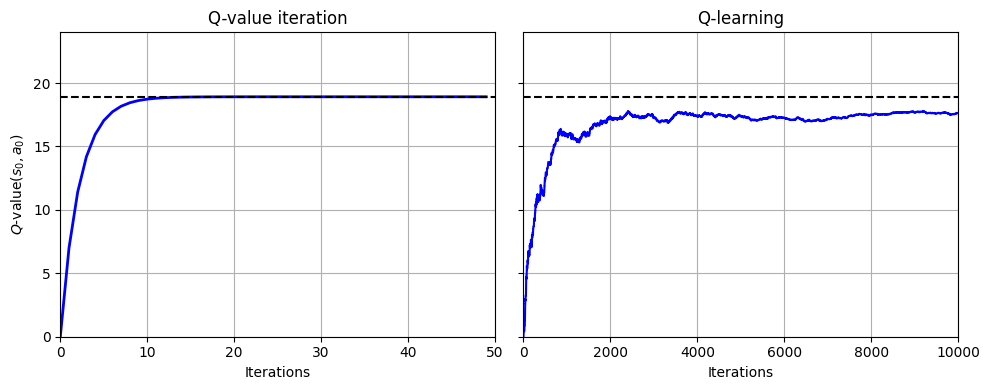

In [37]:
# extra

import matplotlib.pyplot as plt

def init_q_values():
    Q = np.full((3, 3), -np.inf)
    for state, actions in enumerate(possible_actions):
        Q[state, actions] = 0.0
    return Q

# Use whichever variable name you defined earlier
T = transition_prob if "transition_probabilities" in globals() else transition_prob

# 1. Track Q-value iteration (50 iterations)
Q_vi = init_q_values()
history_vi = []
gamma = 0.90

for iteration in range(50):
    history_vi.append(Q_vi[0, 0])
    Q_prev = Q_vi.copy()
    for s in range(3):
        for a in possible_actions[s]:
            Q_vi[s, a] = np.sum([
                T[s][a][sp] * (rewards[s][a][sp] + gamma * Q_prev[sp].max())
                for sp in range(3)
            ])

# 2. Track Q-learning (10,000 iterations)
Q_ql = init_q_values()
history_ql = []
alpha0, decay, state = 0.05, 0.005, 0

for iteration in range(10_000):
    history_ql.append(Q_ql[0, 0])
    action = exploration_policy(state)
    next_state, reward = step(state, action)
    next_value = Q_ql[next_state].max()
    alpha = alpha0 / (1 + iteration * decay)
    Q_ql[state, action] *= 1 - alpha
    Q_ql[state, action] += alpha * (reward + gamma * next_value)
    state = next_state

# 3. Plot both curves side-by-side
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

axes[0].plot(history_vi, color="blue", linewidth=2)
axes[0].axhline(history_vi[-1], color="black", linestyle="--")
axes[0].set_title("Q-value iteration")
axes[0].set_xlabel("Iterations")
axes[0].set_ylabel(r"$Q\text{-value}(s_0, a_0)$")
axes[0].set_xlim(0, 50)
axes[0].set_ylim(0, 24)
axes[0].grid(True)

axes[1].plot(history_ql, color="blue", linewidth=1.5)
axes[1].axhline(history_vi[-1], color="black", linestyle="--")
axes[1].set_title("Q-learning")
axes[1].set_xlabel("Iterations")
axes[1].set_xlim(0, 10000)
axes[1].grid(True)

plt.tight_layout()
plt.show()

**Note**

1.  The Q-learning algorithm is called an off-policy algorithm because the policy being trained is not necessarily the one used during training.

- It is somewhat surprising that Q-learning is capable of learning the optimal policy by just
watching an agent act randomly.


2. The REINFORCE algorithm is on-policy .  

- It explores the world using the policy being trained.




---



## 7.Exploration Policies


Q-Learning , takes a alot of time in short , therefore, a better option is to use the `ε-greedy policy` (ε is epsilon): at each step it acts randomly with
probability ε, or greedily with probability 1 - ε (i.e., choosing the action with the highest Q-value)

**Advantage** :-  


Instead of wandering blindly 100% of the time like our earlier random policy, an $\varepsilon$-greedy policy balances playing smart with trying new things—getting the agent into rewarding parts of the map much faster:

* Focuses on promising paths ($1 - \varepsilon$ probability)

* Keeps checking unknown areas ($\varepsilon$ probability)

* Why $\varepsilon$ shrinks ($1.0 \rightarrow 0.05$): Starting at $\varepsilon = 1.0$ (100% random) makes sense when the agent knows nothing at the start; gradually lowering it to 0.05 shifts the agent to 95% best moves, 5% random exploration once it has learned a solid strategy.




---



**Alternatively**

- rather than relying only on chance for exploration, another approach is to encourage the exploration policy
to try actions that it has not tried much before. This can be implemented as a bonus added to the Q-value estimates , by using this equation:





```
Equation - Q-learning using an exploration function
```

$$Q(s,a) \xleftarrow[\alpha]{} r + \gamma \cdot \max_{a'} f\big(Q(s',a'), N(s',a')\big)$$


In this equation:

* N(s′, a′) counts the number of times the action a′ was chosen in state s′.

* f(Q, N) is an exploration function, such as f(Q, N) = Q + κ/(1 + N), where κ (kappa) is a curiosity hyperparameter
that measures how much the agent is attracted to the unknown

### 7.1 Approximate Q-Learning and Deep Q-Learning


The main problem with Q-learning is that it does not scale well to large (or even medium) MDPs with many states and
actions

The solution is to find a function Qθ(s, a) that approximates the Q-value of any state-action pair (s, a), where the vector θ
parameterizes the function. This is called approximate Q-learning

Approximate Q-Learning:

- Instead of storing exact Q-values in a giant lookup table, you train a parameterized function $Q_{\boldsymbol{\theta}}(s, a)$ to estimate (predict) the Q-values from the state's features. Because the model learns general patterns rather than memorizing individual table rows, it can accurately predict Q-values even for brand-new states it has never visited before.

Deep Q-Learning (DQN):

- This is simply Approximate Q-Learning where the estimation function is a Deep Neural Network (called a Deep Q-Network, or DQN). In PyTorch, you pass the current state into the neural network, it outputs predicted Q-values for all possible actions at once, and you train its weights via gradient descent so those predictions match the Q-learning target ($r + \gamma \max_{a'} Q(s', a')$).

Simple Hinglish mein: Tabular Q-learning ka table sirf chhote games ke liye chalta hai; bade games mein har state ka table banana namumkin hai. Approximate Q-Learning mein table ki jagah ek model use hota hai jo state dekh kar Q-value predict karta hai, aur jab wo model ek Deep Neural Network (PyTorch network) hota hai, toh usi ko Deep Q-Learning (DQN) kehte hain



---





```
Equation - Target Q-value
```



$$y(s,a) = r + \gamma \cdot \max_{a'} Q_{\boldsymbol{\theta}}(s',a')$$

It's the sume of the real reward we got after moving from one state to another + the predicted score for the future , so that we can know whether it's gonna be a dead end or will lead us where we want.

With this target Q-value, we can run a training step using any gradient descent algorithm. In general, we try to minimize
the squared error between the estimated Q-value Qθ(s, a) and the target Q-value y(s, a), or the Huber loss to reduce the
algorithm’s sensitivity to large errors. And that’s the deep Q-learning algorithm

### 7.2 Implementing Deep Q-Learning


The first thing we need is a deep Q-network. In theory, we need a neural net that takes a state-action pair as input, and
outputs an approximate Q-value.

However, in practice it’s much more efficient to use a neural network that takes only a state
as input, and outputs one approximate Q-value for each possible action

In [38]:
# creating NN and it takes state as an input

class DQN(nn.Module):
  def __init__(self):
    super().__init__()
    self.net = nn.Sequential(nn.Linear(4,32), nn.ReLU(),
                             nn.Linear(32,32), nn.ReLU(),
                             nn.Linear(32,2))

  def forward(self,state):
    return self.net(state)


Our DQN is very similar to our earlier policy network, except it outputs a Q-value for each action instead of logits. Now
let’s define a function to choose an action based on this DQN:

In [39]:
# now let's get the Q-values
def choose_dqn_action(model , obs, epsilon =0.0):
  if torch.rand(()) < epsilon: # epsilon greedy policy
    return torch.randint(2, size = ()).item()

  else :
    state = torch.as_tensor(obs)
    Q_values = model(state)
    return Q_values.argmax().item() # optimal according to the DQN



This function takes an environment state (a single observation) and passes it to the neural net to predict the Q-values, then
it simply returns the action with the largest predicted Q-value (argmax()). To ensure that the agent explores the
environment, we use an ε-greedy policy, meaning we choose a random action with probability ε.

Instead of training the DQN based only on the latest experiences, we will store all experiences in a replay buffer (or
replay memory), and we will sample a random training batch from it at each training iteration. This helps reduce the
correlations between the experiences in a training batch, which stabilizes training by making the data distribution more
consistent. Each experience will be represented as a tuple with six elements: a state s, the action a that the agent took, the
resulting reward r, the next state s′ it reached, a boolean indicating whether the episode ended at that point (done), and
finally another boolean indicating whether the episode was truncated at that point. We will also need a function to sample
a random batch of experiences from the replay buffer. It will return a tuple containing six tensors, one for each field:

In [40]:
def sample_experience(replay_buffer, batch_size):
  indices = torch.randint(len(replay_buffer), size = [batch_size])
  batch = [replay_buffer[index] for index in indices.tolist()]
  return [to_tensor([exp[index] for exp in batch]) for index in range(6)]

def to_tensor(data):
  array = np.stack(data)
  dtype = torch.float32 if array.dtype == np.float64 else None
  return torch.as_tensor(array, dtype = dtype)

The sample
_
experiences() function takes a replay buffer and a batch size, and it randomly samples the desired
number of experience tuples from the buffer. Then, for each of the six fields in the experience tuples, it extracts that field
from each experience in the batch, and converts that list to a tensor using the to
_
tensor() function. Lastly, it returns
the list of six tensors. The tensors all have shape [batch size] except for the observation tensors, which have shape
[batch size, 4].

to_tensor(data) ka kaam bas itna hai ki ek field ke saare values (jaise batch ke saare rewards ya saare states) ko lekar PyTorch ka tensor bana de:

The replay buffer can be any data structure that supports appending and indexing, and can limit the size to avoid blowing
up memory during training. For simplicity, we will use a Python deque, from the standard collections package. This
is a double-ended queue


If you set
a size limit, and that limit is reached, appending an element to one end of the queue automatically pops an item from the
other side. This means that each new experience replaces the oldest experience, which is exactly what we want.



---



**TIP**

- Appending and popping items on the ends of a deque is very fast, but random access can be slow when the queue
gets very long (e.g., 100,000 items or more). If you need a very large replay buffer, you should use a circular buffer
instead

Let’s also create a function that will play a full episode using our DQN, and store the resulting experiences in the replay
buffer. We’ll run in eval mode with torch.no
_grad() since we don’t need gradients for now. For logging purposes,
we’ll also make the function sum up all the rewards in the episode and return the result:

Here , we gonna play the game , and fill the experiences , so that's why gonna be using model.eval as we don't want the weigths to be updated or model to learn

In [41]:
def play_record_episode(model, env ,replay_buffer, epsilon, seed = None):
  obs , _info = env.reset(seed = seed)
  total_rewards = 0
  model.eval()
  with torch.no_grad():
    while True:
      action = choose_dqn_action(model, obs, epsilon)
      next_obs, reward, done, truncated , _info = env.step(action)
      experience = (obs, action,reward, next_obs, done , truncated)
      replay_buffer.append(experience)
      total_rewards += reward

      if done or truncated:
        return total_rewards
      obs = next_obs


step(state, action) ek virtual game engine / env hai jo agent ke move par next_state aur reward return karta hai.

Next, let’s create a function that will sample a batch of experiences from the replay buffer and train the DQN by
performing a single gradient descent step on this batch:

Basicaly training the model from the current experiences (collection of experiences/data) we got so far etc. and gonna be updating the nn to get better predictions.

In [44]:
def dqn_training_step(model, optimizer, criterion, replay_buffer, batch_size, discount_factor):
    experiences = sample_experience(replay_buffer, batch_size)
    state, action, reward, next_state, done, truncated = experiences

    with torch.no_grad():
        next_Q_value = model(next_state)
        max_next_Q_value, _ = next_Q_value.max(dim=1)
        running = (~(done | truncated)).float()  # 0 if s' is over, 1 if running
        target_Q_value = reward + running * discount_factor * max_next_Q_value

    all_Q_values = model(state)
    Q_value = all_Q_values.gather(dim=1, index=action.unsqueeze(1))
    loss = criterion(Q_value, target_Q_value.unsqueeze(1))

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

Here’s what’s happening in this code:

1. The function starts by sampling a batch of experiences from the replay buffer.

2. Then it uses the DQN to compute the target Q-value for each experience in the batch. For this, the code
implements `Equation The target Q-value` the DQN is used in inference mode to evaluate all the Q-values for the next state s’,
then we keep only the max Q-value since we assume that the agent will play optimally from now on, and we
multiply this max Q-value with the discount factor.

3. If the episode was over (done or truncated), then the
discounted max Q-value is multiplied by zero since we cannot expect any more rewards. Otherwise, it’s
multiplied by 1 (i.e., unchanged). Lastly, we add the experience’s reward. All of this is performed simultaneously
for all experiences in the batch.

4. Next, the function uses the model again (in training mode this time) to compute all the Q-values for the current
state s, and it uses the gather() method to extract just the Q-value that corresponds to the action that was
actually chosen. Again, this is done simultaneously for all experiences in the batch.


5. Lastly, we compute the loss, which is typically the MSE between the target Q-values and the predicted Q-values,
and we perform an optimizer step to minimize the loss.

Now we can write the main training function and run it

In [45]:
from collections import deque

def train_dqn(model , env , replay_buffer, optimizer, criterion, n_episodes = 800,
              warmup = 30 , batch_size = 32 , discount_factor = 0.95):

  totals = []
  for episode in range(n_episodes):
    epsilon = max(1 - episode / 500 , 0.01)
    seed = torch.randint(0 , 2**32 , size =()).item()

    total_rewards = play_record_episode(model, env , replay_buffer,
                                        epsilon , seed = seed)
    print(f"\rEpisode: {episode + 1}, reward : {total_rewards}", end = " ")
    totals.append(total_rewards)
    if episode >= warmup:
      dqn_training_step(model, optimizer , criterion, replay_buffer,
                        batch_size , discount_factor)
  return totals

torch.manual_seed(42)
dqn = DQN()
optimizer = torch.optim.NAdam(dqn.parameters(), lr = 0.01)
mse = nn.MSELoss()
replay_buffer = deque(maxlen = 100_000)
totals = train_dqn(dqn, env, replay_buffer, optimizer, mse)

Episode: 800, reward : 293.0 

The training algorithm runs for 800 episodes. At each training iteration, we make the DQN play one full episode using the
play_
and
record
_
episode() function, then we run one training step using the dqn
_
training_
step() function.
Note that we only start training after several warmup episodes to ensure that the replay buffer contains plenty of
experiences. We also linearly decrease the epsilon value for the ε-greedy policy from 1.0 down to 0.01 after 500 episodes
(then it remains at 0.01). This way, the agent’s behavior will gradually become less random, focusing more on
exploitation and less on exploration. The function also records the total rewards for each episode, and returns these totals below is the plot

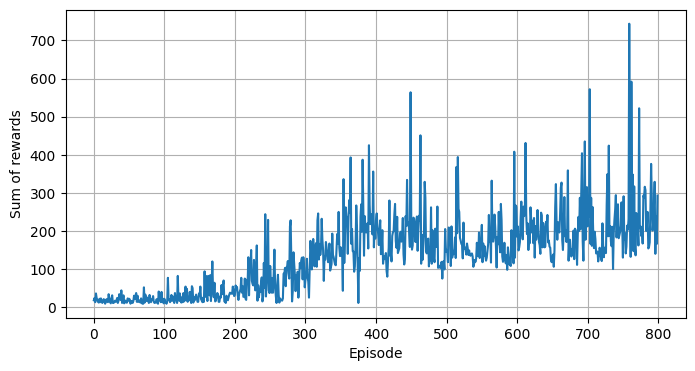

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(totals)
plt.xlabel("Episode")
plt.ylabel("Sum of rewards")
plt.grid(True)
plt.show()

**NOTE**

- Why not plot the loss?
Well, it’s a poor indicator of the model’s performance, so it’s preferable to plot the total
rewards for each episode.

So choose the rewards over loss plot in RL


**SUMMARY_TIME**

The good news - algorithm worked but the bad news - the trainign is unstable , and infact less stable than REINFORCE - and as we had to tweak hyperparams alot such that model to perform this well , also the model was doing decent until 200 episodes and it fetched 200 rewards but after that  terrible until episode ~ 550

`Question` why this DQN unstable

- bcoz the replay buffer is very large.

- in
this basic deep Q-learning implementation, the model is used both to make predictions and to set its own targets, this makes the network unstable.



---



## 8.DQN Improvements

=
let's see how we can improve the network and try to stable to the network

`One approach` - doing training using two DQNs instead of one ,

- the first is the online model, which learns at each step and is used to move the agent around, and the other is the target
model used only to define the targets.

- here the target model is the clone of the online model and it's weights are copied at regular intervals. improvments done with several other tweaks: a very large replay buffer, a tiny learning rate, a very long training time (50
million steps), a very slowly decreasing epsilon (over 1 million steps), and a powerful neural net (a CNN).


`Another approach`

this variant double DQN. The update was based on the observation that the
target network is prone to overestimating Q-values

`Another important` improvement was the introduction of prioritized experience replay (PER) which is Instead of sampling experiences uniformly from the replay buffer,
why not sample important experiences more frequently?

`One reasonable approach` is to measure the magnitude of the TD error δ = r + γ·V(s′) – V(s). A large TD
error indicates that a transition (s, a, s′) is very surprising and thus probably worth learning from.

There’s one catch though: since the samples will be biased toward important experiences, we must compensate for this
bias during training by downweighting the experiences according to their importance, or the model will just overfit the
important experiences.


To be clear, we want important experiences to be sampled more often, but this also means we
must give them a lower weight during training. To do this, we define each experience’s training weight as w = (n P)–β
,
where n is the number of experiences in the replay buffer, and β is a hyperparameter that controls how much we want to
compensate for the importance sampling bias (0 means not at all, while 1 means entirely).

**NOTE**

- DQN variant is the dueling DQN algorithm (DDQN, not to be confused with double DQN, although
both techniques can easily be combined).

These techniques can be combined in various ways, combined six different techniques into an agent called Rainbow, which largely outperformed the state of the art.

why not combine policy gradients with value-based methods to get the best of
both worlds? This is the core idea behind actor-critic algorithms. Let’s discuss them now

### 8.1 Actor-Critic Algorithms

Actor-critics are a family of RL algorithms that combine policy gradients with value-based methods. An actor-critic is
composed of a policy (the actor) and a value network (the critic), which are trained simultaneously. The actor relies on
the critic to estimate the value (or advantage) of actions or states, guiding its policy updates. Since the critic can use a
large replay buffer, it stabilizes training and increases data efficiency. It’s a bit like an athlete (the actor) learning with the
help of a coach (the critic).

**NOTE**
- actor-critic methods support stochastic policies and continuous action spaces, just like policy gradients. So we
do get the best of both worlds.

In [47]:
# Let's implement a basic actor-critic

class ActorCritic(nn.Module):
  def __init__(self):
    super().__init__()
    self.body = nn.Sequential(
        nn.Linear(in_features = 4, out_features = 32),
        nn.ReLU(),
        nn.Linear(in_features = 32 , out_featurs = 32),
        nn.ReLU()
    )
    self.actor_head = nn.Linear(in_features = 32, out_features =1) # outputs action logits
    self.critic_head = nn.Linear(in_features = 32, out_features = 1) # output state values

  def forward(self , state):
    features = self.body(state)
    return self.actor_head(features) , self.critic_head(features)


In the constructor, we build the actor and critic networks. In this implementation, they share the same lower layers (called
the body). This is common practice, as it reduces the total number of parameters and thereby increases data efficiency, but
it also makes training a bit less stable since it couples the actor and critic more closely

Code - working

- The actor network takes a batch of environment states and outputs an action logit for each state (that’s the logit
for action 1, just like for REINFORCE). The critic network estimates the value of each given state. The forward()
method takes a batch of states and runs them through both networks (with a shared body), and returns the action logits
and state values.


`in-short` : the Actor decides which action to take, and the Critic judges how good the current state is.

Now let’s write a function to choose an action. It’s identical to the choose
_
action() function we wrote earlier for the
REINFORCE policy network, except that it also returns the state value estimated by the critic network. This will be
needed for training:

In [48]:
def choose_action_evaluate(model , obs):
  state = torch.as_tensor(obs) # Turns the raw observation obs into a tensor.
  logit , state_value = model(state)
  """
Passes state through the actor-critic network to get action 1's raw score
(logit) and the estimated state value (state_value).
  """

  # Builds a probability distribution for choosing action 1 vs 0 from logit.
  dist = torch.distributions.Bernoulli(logits = logit)

  # Randomly picks action 1 or 0 based on those probabilities.
  action = dist.sample()

  # Gets the log-probability of the action that was picked
  log_prob = dist.log_prob(action)

  #Sends back the chosen action as a plain Python int (0 or 1),
  #  along with its log_prob and state_value
  return int(action.item()), log_prob , state_value

Now let’s see how to train our actor-critic. We’ll start by defining a function that will perform one training step

In [49]:
def ac_training_step(optimizer , criterion , state_value ,
                     target_value, log_prob, critic_weight):

  td_error = target_value - state_value

  actor_loss = - log_prob * td_error.detach()
  critic_loss = criterion(state_value , target_value)

  loss = actor_loss + critic_weight * critic_loss

  optimizer.zero_grad()
  loss.backward()
  optimizer.step()


First, we compute the TD error, which is the difference between the target value y = r + γV(s’) and the state value V(s).
The actor’s loss is the same as in REINFORCE, except that we multiply the log probability by the TD error instead of the
(standardized) return. In other words, we encourage actions that performed better than the value network expected. As for
the critic’s loss, it encourages the critic’s value estimates V(s) to match the target values y (e.g., using the MSE). Lastly,
the overall loss is a weighted sum of the actor’s loss and the critic’s loss. To stabilize training, it’s generally a good idea to
give less weight to the critic’s loss. Then we perform an optimizer step to minimize the loss. Oh, and note that we call
td
_
error.detach() because we don’t want gradient descent to affect the critic network via the actor’s loss.

In [50]:
# We’ll also need a function to compute the target value

def get_target_value(model , next_obs , reward , done , truncated , discount_factor):
  with torch.inference_mode():
    _, _, next_state_value = choose_action_evaluate(model, next_obs)
